# 21. Quickstart for the TensorFlow Core APIs

This quickstart tutorial demonstrates how you can use the TensorFlow Core low-level APIs to build and train a multiple linear regression model that predicts fuel efficiency. It uses the Auto MPG dataset which contains fuel efficiency data for late-1970s and early 1980s automobiles.

You will follow the typical stages of a machine learning process:

1. Load the dataset.
2. Build an input pipeline.
3. Build a multiple linear regression model.
4. Evaluate the performance of the model.

### Setup

Import TensorFlow and other necessary libraries to get started:

In [1]:
import tensorflow as tf
import pandas as pd
import matplotlib
from matplotlib import pyplot as plt
print("TensorFlow version:", tf.__version__)
# Set a random seed for reproducible results
tf.random.set_seed(22)

TensorFlow version: 2.20.0


### Load and preprocess the dataset

Next, you need to load and preprocess the Auto MPG dataset from the UCI Machine Learning Repository. This dataset uses a variety of quantitative and categorical features such as cylinders, displacement, horsepower and weight to predict the fuel efficiencies of automobiles in the late-1970s and early 1980s.

The dataset contains a few unknown values. Make sure to drop any missing values with `pandas.DataFrame.dropna`, and convert the dataset to a `tf.float32` tensor typw with the `tf.convert_to_tensor` and `tf.cast` functions.

In [2]:
url = 'http://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data'
column_names = ['MPG', 'Cylinders', 'Displacement', 'Horsepower', 'Weight', 'Acceleration', 'Model Year', 'Origin']

dataset = pd.read_csv(url, names=column_names, na_values='?', comment='\t', sep=' ', skipinitialspace=True)

In [3]:
dataset = dataset.dropna()
dataset_tf = tf.convert_to_tensor(dataset, dtype=tf.float32)
dataset.tail()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
393,27.0,4,140.0,86.0,2790.0,15.6,82,1
394,44.0,4,97.0,52.0,2130.0,24.6,82,2
395,32.0,4,135.0,84.0,2295.0,11.6,82,1
396,28.0,4,120.0,79.0,2625.0,18.6,82,1
397,31.0,4,119.0,82.0,2720.0,19.4,82,1


Next, split the dataset into training and test sets. Make sure to shuffle the dataset with `tf.random.shuffle` to avoid biased splits.

In [4]:
dataset_shuffled = tf.random.shuffle(dataset_tf, seed=22)
train_data, test_data = dataset_shuffled[100:], dataset_shuffled[:100]
x_train, y_train = train_data[:, 1:], train_data[:, 0]
x_test, y_test = test_data[:, 1:], test_data[:, 0]

In [5]:
type(dataset_shuffled)

tensorflow.python.framework.ops.EagerTensor

In [6]:
type(x_train)

tensorflow.python.framework.ops.EagerTensor

Perform basic feature engineering by one-hot encoding the `"Origin"` feature. The `tf.one_hot` function is useful for transforming this categorical column into 3 separate binary columns.

In [7]:
def onehot_origin(x):
    origin = tf.cast(x[:, -1], tf.int32)
    # Use 'origin - 1' to account for 1-indexed feature
    origin_oh = tf.one_hot(origin - 1, 3)
    x_ohe = tf.concat([x[:, :-1], origin_oh], axis=1)
    return x_ohe

x_train_ohe, x_test_ohe = onehot_origin(x_train), onehot_origin(x_test)
x_train_ohe.numpy()

array([[  4., 140.,  72., ...,   1.,   0.,   0.],
       [  4., 120.,  74., ...,   0.,   0.,   1.],
       [  4., 122.,  88., ...,   0.,   1.,   0.],
       ...,
       [  8., 318., 150., ...,   1.,   0.,   0.],
       [  4., 156., 105., ...,   1.,   0.,   0.],
       [  6., 232., 100., ...,   1.,   0.,   0.]],
      shape=(292, 9), dtype=float32)

In [9]:
# x_test_ohe

This example shows a multiple regression problem with predictors or features on vastly different scales. Therefore, it is beneficial to standardize the data so that each feature has zero mean and unit variance. Use the `tf.reduce_mean` and `tf.math.reduce_std` functions for standardization. The regression model's prediction can then be unstandardized to obtain its value in terms of the original units.

In [10]:
class Normalize(tf.Module):
    def __init__(self, x):
        # Initialize the mean and standard deviation for normalization
        self.mean = tf.math.reduce_mean(x, axis=0)
        self.std = tf.math.reduce_std(x, axis=0)

    def norm(self, x):
        # Normalize the input
        return (x - self.mean) / self.std

    def unnorm(self, x):
        # Unnormalize the input
        return (x * self.std) + self.mean

In [11]:
norm_x = Normalize(x_train_ohe)
norm_y = Normalize(y_train)
x_train_norm, y_train_norm = norm_x.norm(x_train_ohe), norm_y.norm(y_train)
x_test_norm, y_test_norm = norm_x.norm(x_test_ohe), norm_y.norm(y_test)

### Build a machine learning model

Build a linear regression model with the TensorFlow Core APIs. The equation for multiple linear regression is as follows:

**Y = Xw + b**

where

* **Y** (m x 1): target vector
* **X** (m x n): feature matrix
* **w** (n x 1): weight vector
* **b**: bias

By using the `@tf.function` decorator, the corresponding Python code is traced to generate a callable TensorFlow graph. This approach is beneficial for saving and loading the model after training. It can also provide a performance boost for models with many layers and complex operations.

In [12]:
class LinearRegression(tf.Module):
    def __init__(self):
        self.built = False

    @tf.function
    def __call__(self, x):
        # Initiailize the model parameters on the first call
        if not self.built:
            # Randomly generate the weight vector and bias term
            rand_w = tf.random.uniform(shape=[x.shape[-1], 1])
            rand_b = tf.random.uniform(shape=[])
            self.w = tf.Variable(rand_w)
            self.b = tf.Variable(rand_b)
            self.built = True
        y = tf.add(tf.matmul(x, self.w), self.b)
        return tf.squeeze(y, axis=1)

For each example, the model returns a prediction for the input automobile's MPG by computing the weights sum of its features plus a bias term. This prediction can then be unstandardized to obtain its value in terms of the original units.

In [13]:
lin_reg = LinearRegression()
prediction = lin_reg(x_train_norm[:1])
prediction_unnorm = norm_y.unnorm(prediction)
prediction_unnorm.numpy()

array([6.8007317], dtype=float32)

### Define a loss function

Now, define a loss function to evaluate the model's performance during the traininng process.

Since regression problems deal with continuous outputs, the mean squared error (MSE) is an ideal choice for the loss function. The MSE is defined by the following equation:

**MSE = (1 / m) * sum(i=1, m | (^y_i - y_i)^2)**

where

* **^y** :  vector of predictions
* **y** : vector of true targets

The goal of this regression problem is to find the optimal weight vector, w, and bias, b, that minimizes the MSE loss function.

In [14]:
def mse_loss(y_pred, y):
    return tf.reduce_mean(tf.square(y_pred - y))

### Train and evaluate your model

Using mini-batches for training provides both memory efficiency and faster convergence. The `tf.data.Dataset` API has useful functions for batching and shuffling. The API enables you to build complex input pipelines from simple, reusable pieces. Learn more about building TensorFlow input pipelines in this guide:

https://www.tensorflow.org/guide/data

In [15]:
batch_size = 64
train_dataset = tf.data.Dataset.from_tensor_slices((x_train_norm, y_train_norm))
train_dataset = train_dataset.shuffle(buffer_size=x_train.shape[0]).batch(batch_size)
test_dataset = tf.data.Dataset.from_tensor_slices((x_test_norm, y_test_norm))
test_dataset = test_dataset.shuffle(buffer_size=x_test.shape[0]).batch(batch_size)

Next, write a training loop to iteratively update your model's parameters by making use of the MSE loss function and its gradients with respect to the input parameters.

This iterative method is referred to as gradient descent. At each iteration, the model's parameters are updated by taking a step in the opposite direction of their computed gradients. The size of this step is determined by the learning rate, which is a configurable hyperparameter. Recall that the gradient of a function indicates the direction of its steepest ascent; therefore, taking a step in the opposite direction indicates the direction of steepest descent, which ultimately helps to minimize the MSE loss function.

In [16]:
# Set training parameters
epochs = 100
learning_rate = 0.01
train_losses, test_losses = [], []

# Format training loop
for epoch in range(epochs):
    batch_losses_train, batch_losses_test = [], []

    # Iterate through the training data
    for x_batch, y_batch in train_dataset:
        with tf.GradientTape() as tape:
            y_pred_batch = lin_reg(x_batch)
            batch_loss = mse_loss(y_pred_batch, y_batch)
        # Update parameters with respect to the gradient calculations
        grads = tape.gradient(batch_loss, lin_reg.variables)
        for g, v in zip(grads, lin_reg.variables):
            v.assign_sub(learning_rate * g)
        # Keep tracl of batch-level training performance
        batch_losses_train.append(batch_loss)

    # Iterate through the testing data
    for x_batch, y_batch in test_dataset:
        y_pred_batch = lin_reg(x_batch)
        batch_loss = mse_loss(y_pred_batch, y_batch)
        # Keep track of batch-level testing performance
        batch_losses_test.append(batch_loss)

    # Keep track of epoch-level model performance
    train_loss = tf.reduce_mean(batch_losses_train)
    test_loss = tf.reduce_mean(batch_losses_test)
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    if epoch % 10 == 0:
        print(f'Mean squared error for step {epoch}: {train_loss.numpy():0.3f}')

# Output final losses
print(f"\nFinal train loss: {train_loss:0.3f}")
print(f"Final test loss: {test_loss:0.3f}")

Mean squared error for step 0: 2.866
Mean squared error for step 10: 0.453
Mean squared error for step 20: 0.285
Mean squared error for step 30: 0.231
Mean squared error for step 40: 0.209
Mean squared error for step 50: 0.203
Mean squared error for step 60: 0.194
Mean squared error for step 70: 0.184
Mean squared error for step 80: 0.186
Mean squared error for step 90: 0.176

Final train loss: 0.177
Final test loss: 0.157


Plot the changes in MSE loss over time. Calculating performance metrics on a designated validation set or test set ensures the model does not overfit to the training dataset and can generalize well to unseen data.

Text(0.5, 1.0, 'MSE loss vs training iterations')

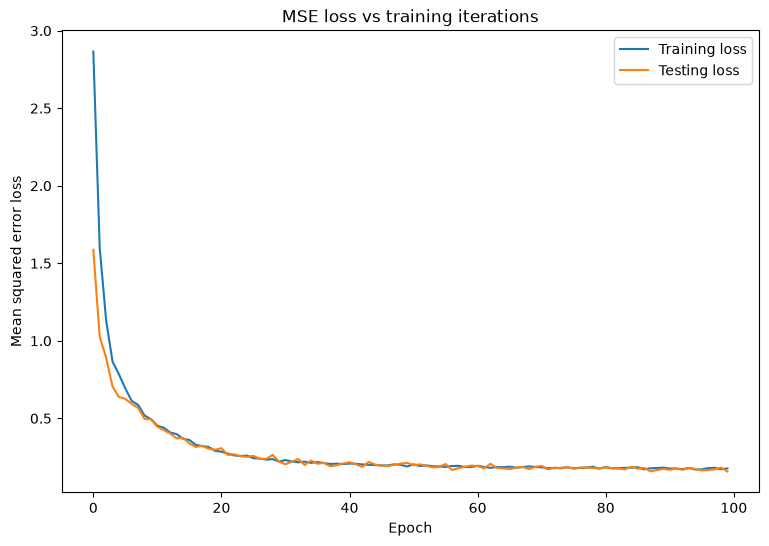

In [17]:
matplotlib.rcParams['figure.figsize'] = [9, 6]

plt.plot(range(epochs), train_losses, label = "Training loss")
plt.plot(range(epochs), test_losses, label = "Testing loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error loss")
plt.legend()
plt.title("MSE loss vs training iterations")

It seems like the model does a good job of fitting the training data while also generalizing well to the unseen test data.

### Save and load the model

Start by making an export module that takes in raw data and performs the following operations:

* Feature extraction
* Normalization
* Prediction
* Unnormalization

In [22]:
class ExportModule(tf.Module):
    def __init__(self, model, extract_features, norm_x, norm_y):
        # Initialize pre and postprocessing functions
        self.model = model
        self.extract_features = extract_features
        self.norm_x = norm_x
        self.norm_y = norm_y

    @tf.function(input_signature=[tf.TensorSpec(shape=[None, None], dtype=tf.float32)])
    def __call__(self, x):
        # Run the ExportModule for new data points
        x = self.extract_features(x)
        x = self.norm_x.norm(x)
        y = self.model(x)
        y = self.norm_y.unnorm(y)
        return y

In [23]:
lin_reg_export = ExportModule(model=lin_reg, extract_features=onehot_origin, norm_x=norm_x, norm_y=norm_y)

If you want to save the model at its current state, use the `tf.saved_model.save` function. To load a saved model for making predictions, use the `tf.saved_model.load` function.

In [24]:
import tempfile
import os

models = tempfile.mkdtemp()
save_path = os.path.join(models, 'lin_reg_export')
tf.saved_model.save(lin_reg_export, save_path)

INFO:tensorflow:Assets written to: C:\Users\yigit\AppData\Local\Temp\tmpqy4fqhca\lin_reg_export\assets


INFO:tensorflow:Assets written to: C:\Users\yigit\AppData\Local\Temp\tmpqy4fqhca\lin_reg_export\assets


In [25]:
lin_reg_loaded = tf.saved_model.load(save_path)
test_preds = lin_reg_loaded(x_test)
test_preds[:10].numpy()

array([28.097498, 26.193336, 33.56437 , 27.719315, 31.787922, 24.014559,
       24.421043, 13.459579, 28.562452, 27.368692], dtype=float32)

### Conclusion

Congratulations! You have trained a regression model using the TensorFlow Core low-level APIs.

For more examples of using TensorFlow Core APIs, check out the following guides:

* Logistic regression for binary classification
* Multi-layer perceptrons for hand-written digit recognition